In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

df = pd.read_excel(
    "Trend Data Combined.ods",
    engine="odf"
)

print(df.shape)
df.head()

(33, 28)


,SAMPLE NO,run_count,distance,elapsed_time,weekly_mileage_change_pct,ground_contact_time,cadence,running_heart_rate,elapsed_pace,stride_length,...,light_sleep,rem_sleep,awake_duration,chronic_load,hrv_deviation,max_streak,hr_drift,max_mileage_increase,avg_mileage_change,status
0,1,0.017130,0.162475,0.704552,0.865043,0.075873,-0.119159,-0.501961,-0.135766,0.001404,...,-1.895662,0.992881,-0.158176,1.17,0.093,18,0.094,31.6,16.0,healthy
1,2,0.029143,-0.039684,-0.237667,-5.338730,-0.398612,0.242248,-0.287247,-0.146275,-0.001396,...,-0.587542,0.593326,0.342603,1.49,-0.039,7,0.011,260.7,76.9,healthy
2,3,-0.051613,-0.367847,-1.595853,-3.280679,-0.299951,0.219348,0.246198,0.676179,-0.001533,...,0.957731,-0.013571,0.667853,0.44,-0.059,18,0.127,-0.6,-25.4,injured
3,4,-0.013348,0.009429,0.015728,7.766181,-0.067715,0.091334,-0.015227,-0.295253,-0.001369,...,-2.252280,0.172191,0.112792,1.28,0.002,16,0.067,97.0,10.6,healthy
4,5,-0.032036,-0.109891,-0.346607,-2.539693,0.141513,0.001112,0.086785,0.961958,-0.000807,...,-0.968632,-0.608676,0.045829,0.76,-0.217,30,0.139,25.4,-13.7,healthy


In [2]:
df = df.dropna(subset=["status"]).copy()

df["status"] = (
    df["status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print(df["status"].value_counts())

status
healthy    28
injured     5
Name: count, dtype: int64


In [3]:
health_features = [
    "resting_heart_rate",
    "stress",
    "nightly_hrv",
    "weekly_hrv",
    "sleep_duration",
    "sleep_score",
    "deep_sleep",
    "light_sleep",
    "rem_sleep",
    "awake_duration",
    "hrv_deviation",
    "hr_drift"
]

running_features = [
    "run_count",
    "distance",
    "elapsed_time",
    "weekly_mileage_change_pct",
    "ground_contact_time",
    "cadence",
    "running_heart_rate",
    "elapsed_pace",
    "stride_length",
    "effort_index",
    "chronic_load",
    "max_streak",
    "max_mileage_increase",
    "avg_mileage_change"
]

X_health = df[health_features]
X_running = df[running_features]

y = df["status"].map({
    "healthy": 0,
    "injured": 1
})

print("Health shape:", X_health.shape)
print("Running shape:", X_running.shape)
print("\nClasses:")
print(y.value_counts())

Health shape: (33, 12)
Running shape: (33, 14)

Classes:
status
0    28
1     5
Name: count, dtype: int64


In [4]:
print("Health missing values:")
print(X_health.isna().sum())

print("\nRunning missing values:")
print(X_running.isna().sum())

Health missing values:
resting_heart_rate    0
stress                0
nightly_hrv           0
weekly_hrv            0
sleep_duration        0
sleep_score           0
deep_sleep            0
light_sleep           0
rem_sleep             0
awake_duration        0
hrv_deviation         0
hr_drift              0
dtype: int64

Running missing values:
run_count                    0
distance                     0
elapsed_time                 0
weekly_mileage_change_pct    0
ground_contact_time          0
cadence                      0
running_heart_rate           0
elapsed_pace                 0
stride_length                0
effort_index                 0
chronic_load                 0
max_streak                   0
max_mileage_increase         0
avg_mileage_change           0
dtype: int64


In [5]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [6]:
def run_random_forest(X, y, category_name):

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        class_weight="balanced",
        random_state=42
    )

    scoring = [
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1"
    ]

    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring
    )

    print(f"\n{category_name} - Random Forest")
    print("-" * 40)

    for metric in scoring:

        scores = results["test_" + metric]

        print(
            f"{metric}: "
            f"{scores.mean():.3f} +/- "
            f"{scores.std():.3f}"
        )

    # Cross-validated predictions
    y_pred = cross_val_predict(
        model,
        X,
        y,
        cv=cv
    )

    # Confusion matrix
    cm = confusion_matrix(
        y,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Healthy",
            "Injured"
        ]
    )

    disp.plot()

    plt.title(
        f"Random Forest - {category_name}"
    )

    plt.show()

    # Classification report
    print(
        classification_report(
            y,
            y_pred,
            labels=[0, 1],
            target_names=[
                "Healthy",
                "Injured"
            ],
            zero_division=0
        )
    )

    return model, results

In [ ]:
rf_health, rf_health_results = run_random_forest(
    X_health,
    y,
    "Health Features"
)

In [ ]:
rf_running, rf_running_results = run_random_forest(
    X_running,
    y,
    "Running Features"
)

In [9]:
rf_health.fit(
    X_health,
    y
)

rf_running.fit(
    X_running,
    y
)

RandomForestClassifier(class_weight='balanced', max_depth=3, n_estimators=200,
                       random_state=42)

               Feature  Importance
8            rem_sleep    0.134710
0   resting_heart_rate    0.104135
9       awake_duration    0.093043
7          light_sleep    0.090980
1               stress    0.082029
6           deep_sleep    0.081752
11            hr_drift    0.077619
4       sleep_duration    0.075629
5          sleep_score    0.074760
10       hrv_deviation    0.068423
3           weekly_hrv    0.061807
2          nightly_hrv    0.055113


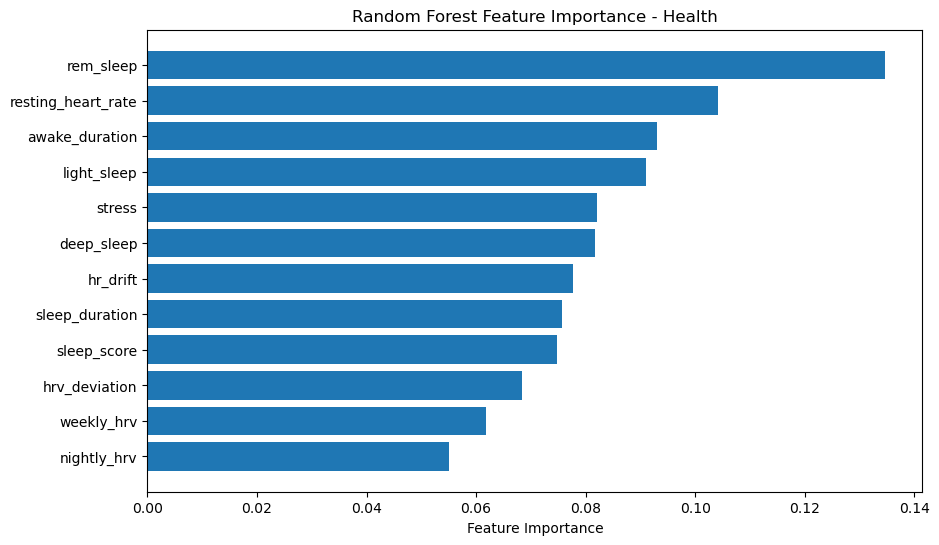

In [10]:
health_importance = pd.DataFrame({
    "Feature": health_features,
    "Importance": rf_health.feature_importances_
})

health_importance = health_importance.sort_values(
    "Importance",
    ascending=False
)

print(health_importance)

plt.figure(figsize=(10, 6))

plt.barh(
    health_importance["Feature"],
    health_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")

plt.title(
    "Random Forest Feature Importance - Health"
)

plt.show()

                      Feature  Importance
0                   run_count    0.133765
9                effort_index    0.109639
3   weekly_mileage_change_pct    0.100908
7                elapsed_pace    0.095217
1                    distance    0.068284
11                 max_streak    0.064513
6          running_heart_rate    0.059213
5                     cadence    0.059116
4         ground_contact_time    0.056666
12       max_mileage_increase    0.054753
10               chronic_load    0.053857
13         avg_mileage_change    0.052972
2                elapsed_time    0.052015
8               stride_length    0.039083


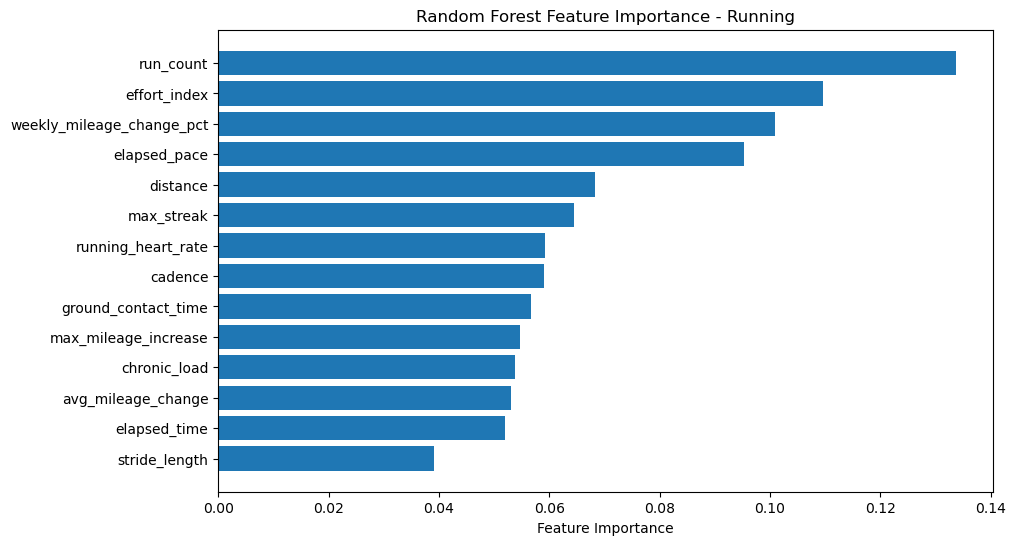

In [11]:
running_importance = pd.DataFrame({
    "Feature": running_features,
    "Importance": rf_running.feature_importances_
})

running_importance = running_importance.sort_values(
    "Importance",
    ascending=False
)

print(running_importance)

plt.figure(figsize=(10, 6))

plt.barh(
    running_importance["Feature"],
    running_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")

plt.title(
    "Random Forest Feature Importance - Running"
)

plt.show()